# Food Delivery Data Analysis Using Python, Pandas, and Matplotlib

**Project objective:** analyse food delivery order data and find practical business insights using
simple statistics, basic Pandas operations and clear Matplotlib charts.

**Four analyses in this notebook**

| # | Analysis | Question it answers |
|---|----------|--------------------|
| 1 | Dataset preparation and cleaning | Is the data usable? |
| 2 | Revenue analysis | Which food category earns the most money? |
| 3 | Popular food categories | Which food category gets the most orders? |
| 4 | Delivery efficiency | Which category is delivered the slowest / fastest? |
| 5 | Customer satisfaction | Do longer deliveries go with lower ratings? |

**Dataset used:** `food_delivery.csv` – keep it in the same folder as this notebook.

**Columns in the dataset**

| Column | Meaning |
|--------|---------|
| `order_id` | unique order number |
| `order_date` | date the order was placed |
| `city` | city where the order was placed |
| `food_category` | category of the food ordered (Pizza, Biryani, ...) |
| `order_value` | bill amount of the order |
| `delivery_time_min` | delivery time in minutes |
| `customer_rating` | rating given by the customer (1 to 5) |
| `order_status` | Delivered / Cancelled / Refunded |

> **Using your own dataset?** If your CSV has different column names, simply replace the column names
> in the code below with the names in your file (for example `order_value` might be called
> `total_amount`). Everything else stays the same.

## 1. Dataset Preparation and Data Cleaning

Before any analysis we must understand the data and fix its problems. In this section we:

1. import the libraries and load the CSV file,
2. look at the data with `head()`, `info()` and `describe()`,
3. find and handle missing values with `isnull()`,
4. remove duplicate rows with `drop_duplicates()`,
5. make sure the numeric columns (order value, delivery time, rating) have numeric data types,
6. keep only the columns needed for the four analyses.

In [1]:
# Step 1.1 - Import the libraries we need
import pandas as pd                 # for loading, cleaning and grouping the data
import numpy as np                  # small helper for numbers
import matplotlib.pyplot as plt     # for drawing the charts

# Show the charts inside the notebook instead of a separate window
%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Step 1.2 - Load the CSV file into a Pandas DataFrame
df = pd.read_csv("food_delivery.csv")

# How big is the dataset?
print("Rows:", df.shape[0], "| Columns:", df.shape[1])

Rows: 1230 | Columns: 8


### 1.1 A first look at the data

In [3]:
# Step 1.3 - head() shows the first 5 rows, so we can see what the data looks like
df.head()

,order_id,order_date,city,food_category,order_value,delivery_time_min,customer_rating,order_status
0,OD100141,2025-05-11,Bengaluru,Burgers,335.42,21.1,4.8,Delivered
1,OD100063,2025-12-14,Bengaluru,South Indian,244.68,37.6,4.6,Delivered
2,OD100669,2025-06-14,Bengaluru,Burgers,315.09,30.9,4.7,Delivered
3,OD100545,2025-04-10,Hyderabad,Burgers,208.52,24.7,5.0,Delivered
4,OD100925,2025-04-05,Bengaluru,Pizza,677.26,30.7,4.5,Delivered


`info()` shows the column names, how many values are present in each column, and the **data type**.
Notice that `customer_rating` is shown as `object` (text) instead of a number – some rows contain
the text `"Not Rated"`. We will fix that in Step 1.7.

In [4]:
# Step 1.4 - Structure of the dataset: columns, data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1230 entries, 0 to 1229
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   order_id           1230 non-null   str    
 1   order_date         1230 non-null   str    
 2   city               1230 non-null   str    
 3   food_category      1230 non-null   str    
 4   order_value        1222 non-null   float64
 5   delivery_time_min  1195 non-null   float64
 6   customer_rating    1190 non-null   str    
 7   order_status       1230 non-null   str    
dtypes: float64(2), str(6)
memory usage: 77.0 KB


`describe()` gives simple statistics (count, mean, min, max, quartiles) for the numeric columns.

In [5]:
# Step 1.5 - Basic statistics of the numeric columns
df.describe()

,order_value,delivery_time_min
count,1222.000000,1195.000000
mean,316.390008,30.080837
std,141.875194,8.716325
min,80.000000,12.000000
25%,206.160000,23.800000
50%,295.035000,29.000000
75%,414.265000,35.450000
max,844.050000,62.500000


### 1.2 Missing values (`isnull()`)

`isnull()` marks every empty cell as `True`, and `.sum()` counts them per column.

In [6]:
# Step 1.6 - How many missing values are there in each column?
df.isnull().sum()

order_id              0
order_date            0
city                  0
food_category         0
order_value           8
delivery_time_min    35
customer_rating      40
order_status          0
dtype: int64

### 1.3 Duplicate records (`duplicated()` / `drop_duplicates()`)

The same order may have been recorded twice. `duplicated()` counts repeated rows and
`drop_duplicates()` keeps only the first copy of each row.

In [7]:
# Step 1.7 - Remove duplicate rows
print("Duplicate rows found:", df.duplicated().sum())

df = df.drop_duplicates()          # keep the first occurrence of every row

print("Rows after removing duplicates:", len(df))

Duplicate rows found: 26
Rows after removing duplicates: 1204


### 1.4 Correct data types

`pd.to_numeric(..., errors="coerce")` converts a column to numbers. Any value that cannot be
converted (like the text `"Not Rated"`) becomes `NaN` = a missing value, which we handle next.

In [8]:
# Step 1.8 - Make sure the numeric columns really are numeric
df["customer_rating"] = pd.to_numeric(df["customer_rating"], errors="coerce")
df["delivery_time_min"] = pd.to_numeric(df["delivery_time_min"], errors="coerce")
df["order_value"] = pd.to_numeric(df["order_value"], errors="coerce")

print(df.dtypes)
print()
print("Missing values after the conversion:")
print(df.isnull().sum())

order_id                 str
order_date               str
city                     str
food_category            str
order_value          float64
delivery_time_min    float64
customer_rating      float64
order_status             str
dtype: object

Missing values after the conversion:
order_id              0
order_date            0
city                  0
food_category         0
order_value           8
delivery_time_min    35
customer_rating      60
order_status          0
dtype: int64


### 1.5 Handling the missing values

| Column | Why it is missing | What we do |
|--------|-------------------|------------|
| `order_value` | the bill amount was not recorded | drop the row – revenue cannot be calculated without it |
| `delivery_time_min` | delivery time was not recorded | drop the row (needed for analyses 4 and 5) |
| `customer_rating` | customer did not rate, or wrote "Not Rated" | drop the row (needed for analysis 5) |

Only a small part of the data is affected, so **dropping** these rows is a simple and safe choice.
(Another option would be to fill them with the column average:
`df["customer_rating"].fillna(df["customer_rating"].mean())`.)

We also keep **only delivered orders**. Cancelled and refunded orders are not real sales,
so they must not be counted as revenue.

After these steps the dataset goes from 1204 rows down to **1055 usable rows**.

In [9]:
# Step 1.9 - Drop rows where our key numeric columns are missing
df = df.dropna(subset=["order_value", "delivery_time_min", "customer_rating"])

# Keep only orders that were actually delivered (remove cancellations / refunds)
df = df[df["order_status"] == "Delivered"]

# Step 1.10 - Keep only the columns needed for the four analyses
df = df[["order_id", "order_date", "city", "food_category",
         "order_value", "delivery_time_min", "customer_rating"]]

# Re-number the rows after all the filtering
df = df.reset_index(drop=True)

print("Cleaned dataset:", df.shape[0], "rows and", df.shape[1], "columns")
df.head()

Cleaned dataset: 1055 rows and 7 columns


,order_id,order_date,city,food_category,order_value,delivery_time_min,customer_rating
0,OD100141,2025-05-11,Bengaluru,Burgers,335.42,21.1,4.8
1,OD100063,2025-12-14,Bengaluru,South Indian,244.68,37.6,4.6
2,OD100669,2025-06-14,Bengaluru,Burgers,315.09,30.9,4.7
3,OD100545,2025-04-10,Hyderabad,Burgers,208.52,24.7,5.0
4,OD100925,2025-04-05,Bengaluru,Pizza,677.26,30.7,4.5


**Cleaning summary:** we removed duplicates, fixed the data types of the three numeric columns and
dropped the rows with missing values, so every remaining row can be used for all four analyses.

---

## 2. Revenue Analysis

**Objective:** understand how revenue is distributed across food categories.

We calculate the **total revenue**, the **revenue per food category** and the **average order value**.

In [10]:
# Step 2.1 - Total revenue and average order value
total_revenue = df["order_value"].sum()      # sum of all order values
average_order_value = df["order_value"].mean()   # mean of the order value column

print("Total revenue       :", round(total_revenue, 2))
print("Total orders        :", len(df))
print("Average order value :", round(average_order_value, 2))

Total revenue       : 331739.99
Total orders        : 1055
Average order value : 314.45


In [11]:
# Step 2.2 - Revenue per food category using groupby() and sum()
revenue_by_category = df.groupby("food_category")["order_value"].sum()

# Sort from the highest revenue to the lowest
revenue_by_category = revenue_by_category.sort_values(ascending=False)

# Share of the total revenue, in percent
revenue_share = (revenue_by_category / total_revenue * 100).round(2)

print("Revenue by category:")
print(revenue_by_category.round(2))
print()
print("Share of total revenue (%):")
print(revenue_share)
print()
print("Highest revenue category:", revenue_by_category.idxmax())

Revenue by category:
food_category
Biryani         92750.35
Pizza           74505.26
Chinese         52875.93
Burgers         42731.55
South Indian    32489.15
Desserts        20806.19
Beverages       15581.56
Name: order_value, dtype: float64

Share of total revenue (%):
food_category
Biryani         27.96
Pizza           22.46
Chinese         15.94
Burgers         12.88
South Indian     9.79
Desserts         6.27
Beverages        4.70
Name: order_value, dtype: float64

Highest revenue category: Biryani


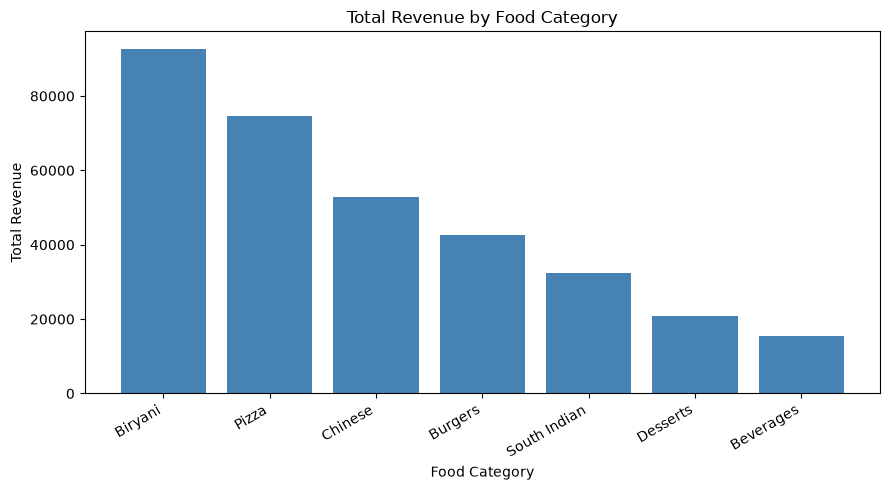

In [12]:
# Step 2.3 - Bar chart: total revenue by food category
plt.figure(figsize=(9, 5))
plt.bar(revenue_by_category.index, revenue_by_category.values, color="steelblue")
plt.title("Total Revenue by Food Category")
plt.xlabel("Food Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Interpretation**

* Total revenue of the cleaned dataset is **331,739.99** from 1055 delivered orders,
  with an **average order value of 314.45**.
* **Biryani** brings in the most revenue: **92,750.35**, which is **27.96%** of all revenue.
* Pizza follows with 74,505.26 (**22.46%**), while **Beverages** earns the least
  (15,581.56, only **4.70%**).
* Biryani and Pizza together produce more than half of the revenue, so the business depends
  heavily on these two categories.

> The order values are treated as revenue because they belong to *delivered* orders only –
> cancelled and refunded orders were removed in Step 1.9.

---

## 3. Popular Food Categories

**Objective:** find out what customers actually order most often.

Here we count orders with `value_counts()` and convert the counts into percentages with the formula

    Percentage of orders = (orders in a category / total orders) x 100

In [13]:
# Step 3.1 - Count the number of orders in each category
orders_by_category = df["food_category"].value_counts()

# Step 3.2 - Percentage of total orders for each category
order_share = (orders_by_category / orders_by_category.sum() * 100).round(2)

print("Orders by category:")
print(orders_by_category)
print()
print("Share of total orders (%):")
print(order_share)
print()
print("Most frequently ordered category:", orders_by_category.idxmax())
print("Total orders counted:", orders_by_category.sum())

Orders by category:
food_category
Biryani         222
Burgers         167
Pizza           162
Chinese         159
South Indian    140
Desserts        106
Beverages        99
Name: count, dtype: int64

Share of total orders (%):
food_category
Biryani         21.04
Burgers         15.83
Pizza           15.36
Chinese         15.07
South Indian    13.27
Desserts        10.05
Beverages        9.38
Name: count, dtype: float64

Most frequently ordered category: Biryani
Total orders counted: 1055


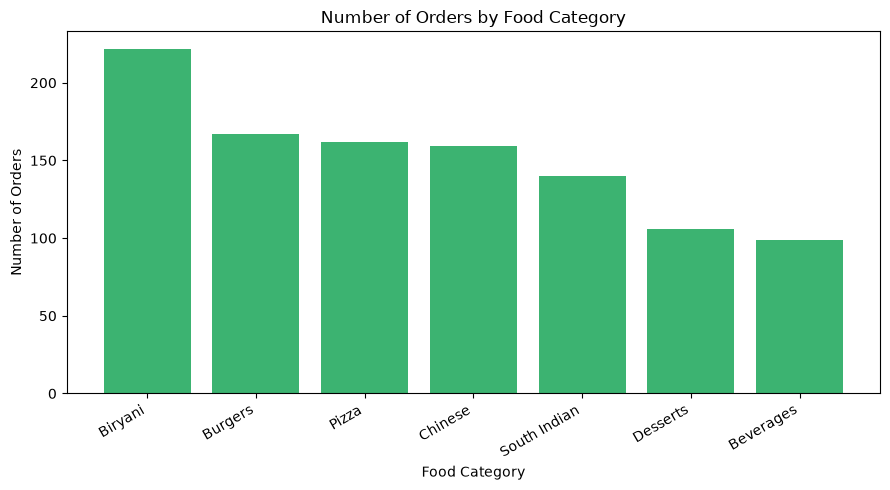

In [14]:
# Step 3.3 - Bar chart: number of orders by food category
plt.figure(figsize=(9, 5))
plt.bar(orders_by_category.index, orders_by_category.values, color="mediumseagreen")
plt.title("Number of Orders by Food Category")
plt.xlabel("Food Category")
plt.ylabel("Number of Orders")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Interpretation**

* **Biryani is the most frequently ordered category** with 222 orders, which is **21.04%**
  of all 1055 orders.
* Burgers (167 orders, 15.83%), Pizza (162, 15.36%) and Chinese (159, 15.07%) are close
  together in the middle.
* **Beverages is ordered the least** – 99 orders, only **9.38%** of the total.

The most popular categories are also the ones that bring in the most revenue, so they must
always be available and well staffed. Beverages are ordered least often but they are also the
cheapest category, so a low order count there is less of a problem.

---

## 4. Delivery Efficiency Analysis

**Objective:** compare delivery performance between food categories.

We use `groupby()` with `mean()` to get the average delivery time per category and compare it with
the average of all orders.

In [15]:
# Step 4.1 - Average delivery time for each food category
avg_delivery_by_category = df.groupby("food_category")["delivery_time_min"].mean()

# Step 4.2 - Overall average delivery time across all orders
overall_avg_delivery = df["delivery_time_min"].mean()

# Sort the categories from the fastest to the slowest
avg_delivery_by_category = avg_delivery_by_category.sort_values()

# Step 4.3 - How much each category differs from the overall average
difference_from_average = (avg_delivery_by_category - overall_avg_delivery).round(2)

print("Average delivery time per category (minutes):")
print(avg_delivery_by_category.round(2))
print()
print("Overall average delivery time (minutes):", round(overall_avg_delivery, 2))
print()
print("Difference from the overall average (minutes):")
print(difference_from_average)
print()
print("Fastest category:", avg_delivery_by_category.idxmin(),
      "->", round(avg_delivery_by_category.min(), 2), "minutes")
print("Slowest category:", avg_delivery_by_category.idxmax(),
      "->", round(avg_delivery_by_category.max(), 2), "minutes")

Average delivery time per category (minutes):
food_category
Beverages       20.18
Desserts        23.59
Burgers         26.16
South Indian    27.58
Pizza           29.77
Biryani         34.41
Chinese         41.44
Name: delivery_time_min, dtype: float64

Overall average delivery time (minutes): 30.12

Difference from the overall average (minutes):
food_category
Beverages       -9.94
Desserts        -6.53
Burgers         -3.96
South Indian    -2.55
Pizza           -0.35
Biryani          4.28
Chinese         11.32
Name: delivery_time_min, dtype: float64

Fastest category: Beverages -> 20.18 minutes
Slowest category: Chinese -> 41.44 minutes


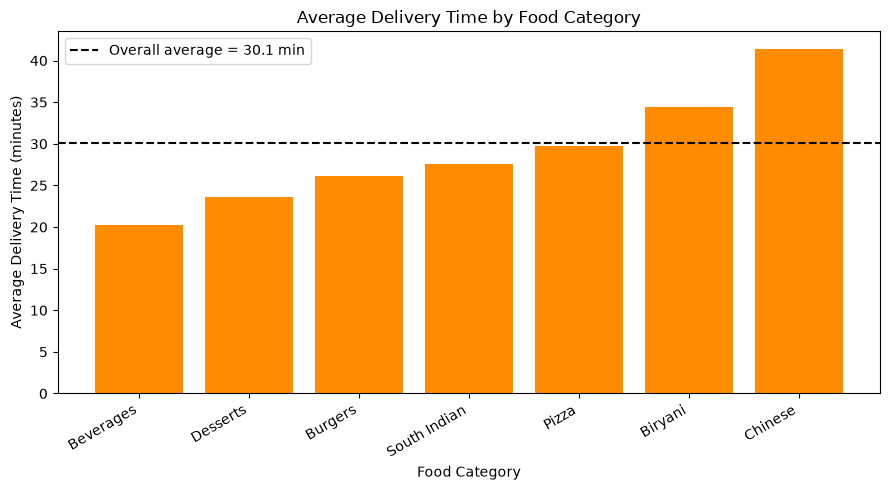

In [16]:
# Step 4.4 - Bar chart: average delivery time by food category
plt.figure(figsize=(9, 5))
plt.bar(avg_delivery_by_category.index, avg_delivery_by_category.values, color="darkorange")
plt.axhline(overall_avg_delivery, color="black", linestyle="--",
            label="Overall average = " + str(round(overall_avg_delivery, 1)) + " min")
plt.title("Average Delivery Time by Food Category")
plt.xlabel("Food Category")
plt.ylabel("Average Delivery Time (minutes)")
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation**

* The overall average delivery time is **30.12 minutes**.
* **Chinese is the slowest category**: 41.44 minutes, which is **11.32 minutes above** the
  overall average.
* Biryani is the next slowest (34.41 minutes, +4.28) – not surprising, because it is also the
  most ordered category.
* **Beverages is the fastest** (20.18 minutes, **9.94 minutes below average**), followed by
  Desserts (23.59) and Burgers (26.16).
* The gap between the fastest (Beverages) and the slowest (Chinese) category is about
  **21 minutes**, which is a large difference.

**Important:** a slower category does **not** prove that the food itself causes the delay.
Distance to the restaurant, traffic, order size and preparation time can all matter. Chinese
food is often cooked to order and Biryani is prepared in large batches with a long preparation
time – these are possible explanations that the data alone cannot confirm.

---

## 5. Customer Satisfaction Analysis

**Objective:** check whether longer delivery times go together with lower customer ratings.

We split the orders into two groups:

* **faster than average** – `delivery_time_min` is less than the overall average,
* **average or slower** – `delivery_time_min` is greater than or equal to the overall average.

Then we compare the average rating of the two groups.

In [17]:
# Step 5.1 - Split the orders into two groups using the overall average delivery time
# (all rows here are valid: they already have both a delivery time and a rating)
fast_orders = df[df["delivery_time_min"] < overall_avg_delivery]
slow_orders = df[df["delivery_time_min"] >= overall_avg_delivery]

# Step 5.2 - Average rating of each group
fast_rating = fast_orders["customer_rating"].mean()
slow_rating = slow_orders["customer_rating"].mean()

# Step 5.3 - Difference between the two averages
rating_difference = fast_rating - slow_rating

print("Faster than average :", len(fast_orders), "orders | average rating",
      round(fast_rating, 2))
print("Average or slower   :", len(slow_orders), "orders | average rating",
      round(slow_rating, 2))
print()
print("Difference (fast - slow):", round(rating_difference, 2), "stars")

Faster than average : 575 orders | average rating 4.75
Average or slower   : 480 orders | average rating 4.44

Difference (fast - slow): 0.31 stars


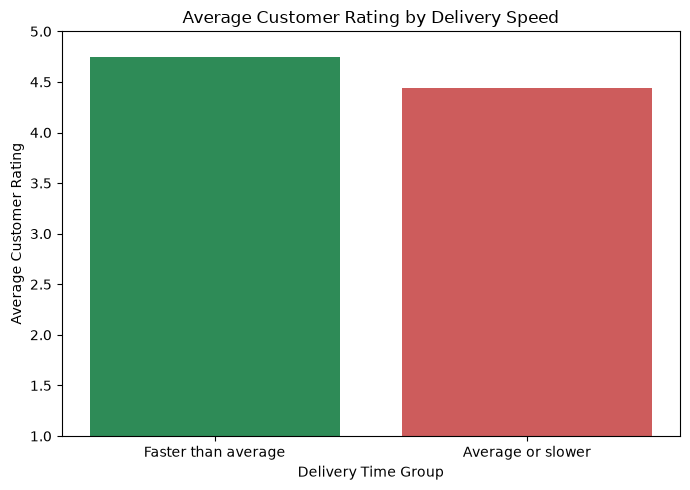

In [18]:
# Step 5.4 - Bar chart comparing the two average ratings
group_names = ["Faster than average", "Average or slower"]
group_ratings = [fast_rating, slow_rating]

plt.figure(figsize=(7, 5))
plt.bar(group_names, group_ratings, color=["seagreen", "indianred"])
plt.title("Average Customer Rating by Delivery Speed")
plt.xlabel("Delivery Time Group")
plt.ylabel("Average Customer Rating")
plt.ylim(1, 5)
plt.tight_layout()
plt.show()

**Interpretation**

* Orders delivered **faster than the average** (575 orders) have an average rating of **4.75**.
* Orders delivered at or **slower than the average** (480 orders) have an average rating of **4.44**.
* The difference is **0.31 stars** in favour of the faster group.

So in this dataset, slower deliveries do go together with lower customer satisfaction.

**Important:** this is an **association, not proof of cause and effect**. Other factors (wrong
items, food quality, packaging, price) may also affect the rating. The analysis only shows that
delivery speed and satisfaction move together in this dataset.

---

## 6. Final Results and Conclusion

The cell below prints the answers to the four main questions.

In [19]:
# Step 6.1 - Answers to the four main questions, calculated from the cleaned data
print("1. Highest revenue category :", revenue_by_category.idxmax(),
      "->", round(revenue_by_category.max(), 2),
      "(" + str(revenue_share.max()) + "% of total revenue)")
print("2. Most ordered category    :", orders_by_category.idxmax(),
      "->", orders_by_category.max(), "orders",
      "(" + str(order_share.max()) + "% of all orders)")
print("3. Longest average delivery :", avg_delivery_by_category.idxmax(),
      "->", round(avg_delivery_by_category.max(), 2), "minutes",
      "(overall average:", round(overall_avg_delivery, 2), "minutes)")
print("4. Slow deliveries rating   :", round(slow_rating, 2),
      "vs fast deliveries:", round(fast_rating, 2),
      "-> difference of", round(rating_difference, 2), "stars")

1. Highest revenue category : Biryani -> 92750.35 (27.96% of total revenue)
2. Most ordered category    : Biryani -> 222 orders (21.04% of all orders)
3. Longest average delivery : Chinese -> 41.44 minutes (overall average: 30.12 minutes)
4. Slow deliveries rating   : 4.44 vs fast deliveries: 4.75 -> difference of 0.31 stars


### Summary of the four analyses

| Question | Answer from the data |
|----------|----------------------|
| 1. Which category generates the highest revenue? | **Biryani** – 92,750.35, i.e. **27.96%** of the total revenue of 331,739.99 |
| 2. Which category receives the most orders? | **Biryani** – 222 orders, i.e. **21.04%** of all 1055 delivered orders |
| 3. Which category has the longest average delivery time? | **Chinese** – 41.44 minutes, against an overall average of 30.12 minutes |
| 4. Is there a relationship between delivery time and ratings? | **Yes, an association** – faster-than-average orders average **4.75** stars, slower ones **4.44** stars (a gap of 0.31) |

### Recommendations

1. **Protect and grow Biryani and Pizza.** These two categories together produce about half of
   all revenue and about a third of all orders. Keeping them always available, well staffed
   during peak hours and well promoted protects the largest part of the business.
2. **Investigate the Chinese category's delivery time.** At 41.44 minutes it is 11.32 minutes
   above the overall average – the largest gap of any category. Check preparation time,
   restaurant distance and rider availability for these orders before changing anything else.
3. **Treat delivery speed as a satisfaction lever.** Orders faster than the average are rated
   0.31 stars higher. Reducing long delivery times (better routing, more riders at peak hours,
   realistic delivery-time promises in the app) is a practical way to raise customer satisfaction.

**Note:** all results are calculated from the cleaned `food_delivery.csv` file (1055 delivered
orders with valid values). The relationships found here are associations in this dataset and
not proof of causation.